# Calculate the Impact Score per Variant

In [1]:
# imports
import os
import polars as pl
import pandas as pd
import numpy as np
from tqdm import tqdm
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import umap
from functools import reduce
import operator
from adjustText import adjust_text
import sys
from tqdm import tqdm
from scipy.stats import spearmanr, pearsonr, mannwhitneyu

sys.path.append("../../../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../1_snakemake_pipeline/2025_varchamp_snakemake")
from img_utils import *

from matplotlib.patches import Patch
import matplotlib.font_manager as fm

# Force TrueType font embedding (Type 42)
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

font_path = "../../../../1_allele_collection/4_manuscript_figures/ARIAL.TTF"
fm.fontManager.addfont(font_path)

font_prop = fm.FontProperties(fname=font_path)
# Set font family to one of the accepted fonts
plt.rcParams.update({
    "font.family": font_prop.get_name(),
    "font.sans-serif": ["ARIAL"],
    "font.size": 12,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

sns.set_style(style='white')
sns.set_context("notebook", font_scale=.9)

## 1. Loading data

### 1.1 Read in the classifier metrics

In [2]:
## classification results in SM pipeline
SM_CLASS_RES_DIR = CLASS_RESULTS_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells"
FEAT = "GFP"
MISLOCALIZED_LABEL = "img_pheno_hit"

In [4]:
imaging_summary_clinvar = pl.read_csv("../../3_outputs/1_imaging_phenotype_summary_clinvar.tsv", separator="\t", infer_schema_length=10000000)
imaging_summary_clinvar_hits = imaging_summary_clinvar.filter(
    pl.col(MISLOCALIZED_LABEL)==1
)
allele_list = list(imaging_summary_clinvar_hits["gene_variant"]) + list(imaging_summary_clinvar_hits["Gene"].unique())
bio_reps = list(imaging_summary_clinvar_hits["Metadata_Bio_Batch"].unique())

### 1.2 Loading CellProfiler Features

In [5]:
allele_meta_df = pl.DataFrame()
allele_meta_df_dict, img_well_qc_sum_dict = {}, {}

for bio_rep, bio_rep_batches in BIO_REP_BATCHES_DICT.items():
    if (bio_rep == "2025_06_Batch_18-19"):
        continue
        
    for batch_id in bio_rep_batches:
        allele_meta_df_batch = pl.DataFrame()
        platemaps = [file for file in os.listdir(PLATEMAP_DIR.format(batch_id=batch_id)) if file.endswith(".txt")]
        for platemap in platemaps:
            platemap_df = pl.read_csv(os.path.join(PLATEMAP_DIR.format(batch_id=batch_id), platemap), separator="\t", infer_schema_length=100000)
            allele_meta_df_batch = pl.concat([allele_meta_df_batch, 
                                        platemap_df.filter((pl.col("node_type").is_not_null()))], # (~pl.col("node_type").is_in(["TC","NC","PC"]))&
                                        how="diagonal_relaxed").sort("plate_map_name")
            allele_meta_df_batch = allele_meta_df_batch.with_columns(pl.col("plate_map_name").alias("plate_map")) ## str.split('_').list.get(0).
            # display(allele_meta_df.head())
        allele_meta_df = pl.concat([
            allele_meta_df,
            allele_meta_df_batch
        ], how="diagonal_relaxed")#.sort("plate_map_name") ## (~pl.col("node_type").is_in(["TC","NC","PC"]))&
    allele_meta_df_dict[bio_rep] = allele_meta_df_batch

    img_well_qc_sum = pl.read_parquet(f"{IMGS_QC_METRICS_DIR}/{bio_rep}/plate-well-level_img_qc_sum.parquet")
    img_well_qc_sum = img_well_qc_sum.with_columns(
        pl.col("channel").replace("DAPI", "DNA").alias("channel")
    )
    img_well_qc_sum_morph = img_well_qc_sum.filter(pl.col("channel")!="GFP")
    img_well_qc_sum_morph = img_well_qc_sum_morph.group_by(["plate","well"]).agg(
        pl.col("is_bg").max().alias("is_bg"),
        pl.col("s2n_ratio").mean().alias("s2n_ratio")
    ).with_columns(pl.lit("Morph").alias("channel"))
    img_well_qc_sum = pl.concat([
        img_well_qc_sum.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
        img_well_qc_sum_morph.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
    ], how="vertical_relaxed")
    img_well_qc_sum_dict[bio_rep] = img_well_qc_sum

In [6]:
## QC-ed PQ files
ALL_PROF_QC = PROF_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier.parquet"
PASS_QC_PROF_PQ = PROF_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells.parquet"

In [7]:
# Paths
ref_var_cell_qc_prof_df = pl.DataFrame()
target_gene_alleles = []
meta_cols = [
    "Metadata_CellID",
    "Metadata_gene_allele",
    "Metadata_Well",
    "Metadata_Plate",
    "Metadata_node_type"
]

# Get meta features
for bio_rep in bio_reps:
    if (bio_rep == "2025_06_Batch_18-19"):
        continue
    bio_rep_batches = BIO_REP_BATCHES_DICT[bio_rep]
    ## ONLY grep the allele come from the bio-rep
    allele_batch_df = imaging_summary_clinvar.filter(pl.col("Metadata_Bio_Batch")==bio_rep)
    batch_allele_list = list(allele_batch_df["gene_variant"]) + list(allele_batch_df["Gene"].unique())
    for batch_id in bio_rep_batches:
        batch_alleles = (
            pl.scan_parquet(
                PASS_QC_PROF_PQ.format(batch_id=batch_id)
            )
            .filter(pl.col("Metadata_gene_allele").is_in(batch_allele_list))
            .with_columns(
                pl.concat_str(
                    [
                        "Metadata_Plate",
                        "Metadata_Well",
                        "Metadata_ImageNumber",
                        "Metadata_ObjectNumber",
                    ],
                    separator="_",
                ).alias("Metadata_CellID")
            )
        ).collect()
        feat_cols = [col for col in batch_alleles.columns if (FEAT.lower() in col.lower())]
        batch_alleles = batch_alleles.join(
            img_well_qc_sum_dict[bio_rep].filter(pl.col("channel")==FEAT).select(pl.col("plate", "well", "is_bg")),
            left_on=["Metadata_Plate", "Metadata_Well"],
            right_on=["plate", "well"]
        ).filter(
            ~pl.col("is_bg")
        ).select(pl.col(feat_cols+meta_cols))
        ref_var_cell_qc_prof_df = pl.concat([ref_var_cell_qc_prof_df, batch_alleles], how="diagonal_relaxed")

### 1.3 Calculate the Impact Score between VAR and WT

The similarity between two profiles is measured by the Pearson correlation coefficient (CC) and is used to assess technical replicate reproducibility of the perturbations with more than one technical replicate.

The Impact Score (IS) for each wild-type/mutant pair is then defined as the (1-CC)/2 in which CC is the correlation coefficient between the wild-type and the mutant replicate-level profiles on each same plate. 

In [8]:
lf = (
        ref_var_cell_qc_prof_df.lazy()
        # .drop_nulls()                       # drop rows with any null
)
feat_cols = [c for c in lf.collect_schema().names()
                 if not c.startswith("Metadata_")]
well_profiles = (
    lf.group_by("Metadata_Plate", "Metadata_Well", "Metadata_gene_allele")
    .agg(*[pl.median(c).alias(c) for c in feat_cols])
)

In [9]:
# ------------------------------------------------------------------
# 3.  Iterate over alleles, compute IS plate-by-plate
# ------------------------------------------------------------------
# Manual correlation calculation for concatenated features
# Option 3: More robust version with null handling
def row_correlation(orig_vals, mut_vals):
    """Calculate correlation between two lists of values"""
    if len(orig_vals) != len(mut_vals) or len(orig_vals) < 2:
        return None
    
    # Handle different data types and nulls
    orig_clean = []
    mut_clean = []
    
    for orig, mut in zip(orig_vals, mut_vals):
        # Skip if either value is None or NaN
        if orig is None or mut is None:
            continue
        
        # Try to convert to float and check for NaN
        try:
            orig_float = float(orig)
            mut_float = float(mut)
            
            # Skip if either is NaN
            if np.isnan(orig_float) or np.isnan(mut_float):
                continue
                
            orig_clean.append(orig_float)
            mut_clean.append(mut_float)
        except (ValueError, TypeError):
            # Skip non-numeric values
            continue
    
    # Need at least 2 valid pairs for correlation
    if len(orig_clean) < 2:
        return None
    
    # Calculate correlation
    return np.corrcoef(orig_clean, mut_clean)[0, 1]
        
records = []
for mut in tqdm(list(imaging_summary_clinvar["gene_variant"])):
    ref = mut.split("_")[0]
    # Profiles of reference and mutant on the same plate
    joined = (
        well_profiles
        .filter(pl.col("Metadata_gene_allele") == ref)
        .join(
            well_profiles.filter(pl.col("Metadata_gene_allele") == mut),
            on=["Metadata_Plate"],
            suffix="_mut",
        )
    )

    # display(joined.collect())
    if joined.select(pl.len()).collect().item() == 0:
        # no matching wells at all
        records.append({"gene_variant": mut, "impact_score": None})
        continue
    # plate_cc = (
    #     joined
    #     .group_by("Metadata_Plate")
    #     .agg(
    #         pl.corr(
    #             pl.concat_list(feat_cols),
    #             pl.concat_list([f"{c}_mut" for c in feat_cols]),
    #         ).alias("cc")
    #     )
    #     .filter(pl.col("cc").is_not_null())
    # )
    
    plate_cc = (
        joined
        .group_by("Metadata_Plate")
        .agg(pl.all())
        .with_columns(
            pl.struct([
                pl.concat_list(feat_cols).alias("orig"),
                pl.concat_list([f"{c}_mut" for c in feat_cols]).alias("mut")
            ]).map_elements(
                lambda x: row_correlation(x["orig"], x["mut"]),
                return_dtype=pl.Float64
            ).alias("cc")
        )
        .filter(pl.col("cc").is_not_null())
        .select(["Metadata_Plate", "cc"])
    )
    # display(plate_cc.collect())
    
    # Median CC -> Impact Score
    median_cc = plate_cc.select(pl.median("cc")).collect().item()
    iscore = (1.0 - median_cc) / 2.0 if median_cc is not None else None
    records.append({"gene_variant": mut, "impact_score": iscore})

  0%|          | 0/806 [00:00<?, ?it/s]

100%|██████████| 806/806 [07:31<00:00,  1.79it/s]


In [ ]:
# records_df = pl.DataFrame(records)
# records_df.write_csv("../../3_outputs/1_img_pheno_variants_impact_scores.tsv", separator="\t")

## 2. Compare IS with AUROC

In [15]:
records_df = pl.read_csv("../../3_outputs/1_img_pheno_variants_impact_scores.tsv", separator="\t")
records_df = records_df.join(
    imaging_summary_clinvar,
    on="gene_variant"
)

records_pandas = records_df.to_pandas()
records_pandas["impact_score_rank"] = records_pandas["impact_score"].rank()
records_pandas["img_pheno_score_rank"] = records_pandas["img_pheno_score"].rank()

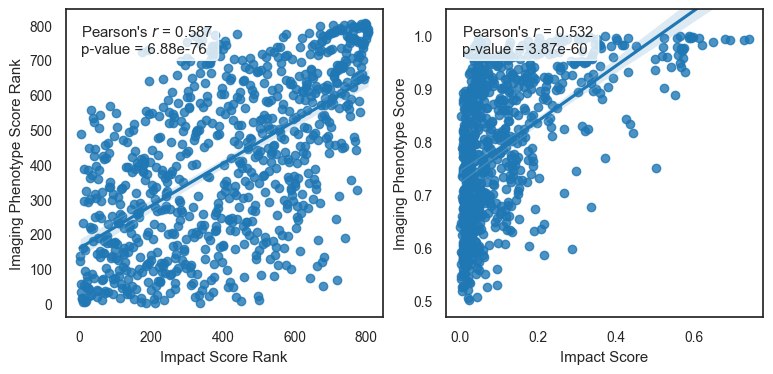

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(9,4))
sns.regplot(data=records_pandas,
            x="impact_score_rank", 
            y="img_pheno_score_rank", 
            truncate=True,
            robust=True,
            ax=ax[0])
ax[0].set_xlabel("Impact Score Rank")
ax[0].set_ylabel("Imaging Phenotype Score Rank")
spearman_corr, p_value = pearsonr(records_pandas["impact_score_rank"], 
                                  records_pandas["img_pheno_score_rank"],
                            #       nan_policy="omit"
                            )
ax[0].text(0.05, 0.95, f"Pearson's $r$ = {spearman_corr:.3f}\np-value = {p_value:.3g}", 
       transform=ax[0].transAxes, verticalalignment='top',
       bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

sns.regplot(data=records_pandas, 
            x="impact_score", 
            y="img_pheno_score", 
            truncate=True,
            robust=True,
            # scatter=False,
            # fit_reg=False,
            ax=ax[1]
)
ax[1].set_ylim(None, 1.05)
ax[1].set_xlabel("Impact Score")
ax[1].set_ylabel("Imaging Phenotype Score")
# Calculate Spearman correlation
spearman_corr, p_value = pearsonr(records_pandas["impact_score"], 
                                  records_pandas["img_pheno_score"],
                            #       nan_policy="omit"
                            )

ax[1].text(0.05, 0.95, f"Pearson's $r$ = {spearman_corr:.3f}\np-value = {p_value:.3g}", 
       transform=ax[1].transAxes, verticalalignment='top',
       bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.subplots_adjust(wspace=0.2)
plt.show()

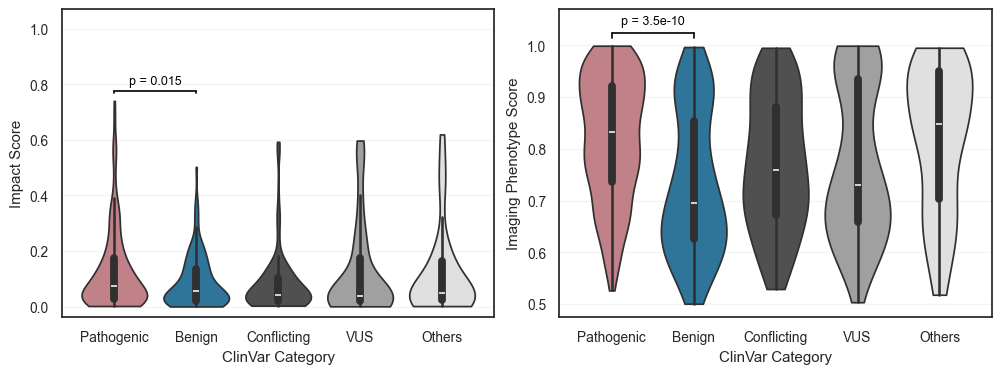

In [17]:
records_df_plot = records_df.filter(
    ~(pl.col("clinvar_clnsig_clean").is_in(["6_No_ClinVar", "5_Others"]))
).with_columns(
    pl.col("clinvar_clnsig_clean").alias("ClinVar Category"),
    pl.col("impact_score").alias("Impact Score"),
    pl.col("AUROC_Mean_GFP").alias("GFP AUROC"),
)

fig, axes = plt.subplots(1,2,figsize=(12, 4))

# sns.kdeplot(
#     data=imaging_summary_clinvar.to_pandas(),
#     x="AUROC_Mean_GFP",
#     hue="clinvar_clnsig_clean",
#     palette=clinvar_palette_old,
#     common_norm=False,
#     hue_order=sorted(clinvar_palette_old.keys()),
#     ax=axes[0]
# )
# axes[0].grid(alpha=.2)
# sns.kdeplot(
#     data=imaging_summary_clinvar.to_pandas(),
#     x="AUROC_Mean_GFP",
#     hue="inheritance_pattern",
#     palette="Set2",
#     common_norm=False,
#     # hue_order=sorted(clinvar_palette_old.keys()),
#     ax=axes[1],
#     warn_singular=False
# )
# axes[1].grid(alpha=.2)

## --- impact_score panel ---
sub = records_df_plot.filter(
    pl.col("clinvar_clnsig_clean").is_in(["Pathogenic", "Benign"])
).drop_nulls("impact_score").to_pandas()
x = sub.loc[sub["clinvar_clnsig_clean"] == "Pathogenic", "impact_score"].values
y = sub.loc[sub["clinvar_clnsig_clean"] == "Benign", "impact_score"].values
stat, p = mannwhitneyu(x, y, alternative="two-sided")
p_text = f"p = {p:.2g}"

sns.violinplot(
    data=records_df_plot.to_pandas(),
    y="Impact Score",
    x="ClinVar Category",
    hue="clinvar_clnsig_clean",
    palette=palette_dict["clinvar_clnsig_clean"],
    order=[c for c in clinvar_order_dict["original"] if "Likely" not in c],
    # records_df_plot.group_by(
    #     "clinvar_clnsig_clean"
    # ).agg(
    #     pl.median("impact_score").alias("clinvar_median")
    # ).sort("clinvar_median", descending=True)["clinvar_clnsig_clean"]
    hue_order=sorted(palette_dict["clinvar_clnsig_clean"].keys()),
    ax=axes[0],
    cut=0
)
axes[0].grid(alpha=.2, axis="y")
# xtick_inher = axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=60, ha="right")
# # quick positions: middle of the two categories
# box_x = {
#     "1_Pathogenic": axes[0].get_xticks()[0],
#     "2_Benign":     axes[0].get_xticks()[1]
# }
# mid = (box_x["1_Pathogenic"] + box_x["2_Benign"]) / 2
# rng = sub["impact_score"].max() - sub["impact_score"].min()
# top = sub["impact_score"].max() + 0.05 * rng
# print(sub["impact_score"].max())
# axes[0].text(mid, top, p_text, ha="center", va="bottom", color="black")

# -------------------------------------------------
# 3. bracket + text
# -------------------------------------------------
# x-positions of the two boxes (0 and n-2 in current order)
x1 = axes[0].get_xticks()[0]          # 1_Pathogenic
x2 = axes[0].get_xticks()[1]         # 2_Benign
y_top = sub["impact_score"].max() + 0.05 * (sub["impact_score"].max() - sub["impact_score"].min())

# horizontal bracket
axes[0].plot([x1, x2], [y_top, y_top], lw=1.2, color="black")
# short vertical caps
cap = 0.01
axes[0].plot([x1, x1], [y_top - cap, y_top], lw=1.2, color="black")
axes[0].plot([x2, x2], [y_top - cap, y_top], lw=1.2, color="black")

# p-value text
axes[0].text((x1 + x2) / 2, y_top + 0.01, p_text,
             ha="center", va="bottom", color="black", fontsize=9)
# ensure space for the bracket
axes[0].set_ylim(None,1.07)

sns.violinplot(
    data=records_df_plot.to_pandas(),
    y="img_pheno_score",
    x="ClinVar Category",
    hue="clinvar_clnsig_clean",
    palette=palette_dict["clinvar_clnsig_clean"],
    order=[c for c in clinvar_order_dict["original"] if "Likely" not in c],
    # order=records_df_plot.group_by(
    #     "clinvar_clnsig_clean"
    # ).agg(
    #     pl.median("AUROC_Mean_GFP").alias("clinvar_median")
    # ).sort("clinvar_median", descending=True)["clinvar_clnsig_clean"],
    hue_order=[c for c in clinvar_order_dict["original"] if "Likely" not in c],
    ax=axes[1],
    cut=0
)
axes[1].set_ylabel("Imaging Phenotype Score")
## --- impact_score panel ---
sub = records_df_plot.filter(
    pl.col("clinvar_clnsig_clean").is_in(["Pathogenic", "Benign"])
).drop_nulls("img_pheno_score").to_pandas()
x = sub.loc[sub["clinvar_clnsig_clean"] == "Pathogenic", "img_pheno_score"].values
y = sub.loc[sub["clinvar_clnsig_clean"] == "Benign", "img_pheno_score"].values
stat, p = mannwhitneyu(x, y, alternative="two-sided")
p_text = f"p = {p:.2g}"

x1 = axes[1].get_xticks()[0]          # 1_Pathogenic
x2 = axes[1].get_xticks()[1]         # 2_Benign
y_top = sub["img_pheno_score"].max() + 0.05 * (sub["img_pheno_score"].max() - sub["img_pheno_score"].min())

# horizontal bracket
axes[1].plot([x1, x2], [y_top, y_top], lw=1.2, color="black")
# short vertical caps
cap = 0.01
axes[1].plot([x1, x1], [y_top - cap, y_top], lw=1.2, color="black")
axes[1].plot([x2, x2], [y_top - cap, y_top], lw=1.2, color="black")
# p-value text
axes[1].text((x1 + x2) / 2, y_top + 0.01, p_text,
             ha="center", va="bottom", color="black", fontsize=9)

# xtick_inher = axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=60, ha="right")
axes[1].grid(alpha=.2, axis="y")
# ensure space for the bracket
axes[1].set_ylim(None,1.07)
plt.subplots_adjust(wspace=.15)
plt.show()

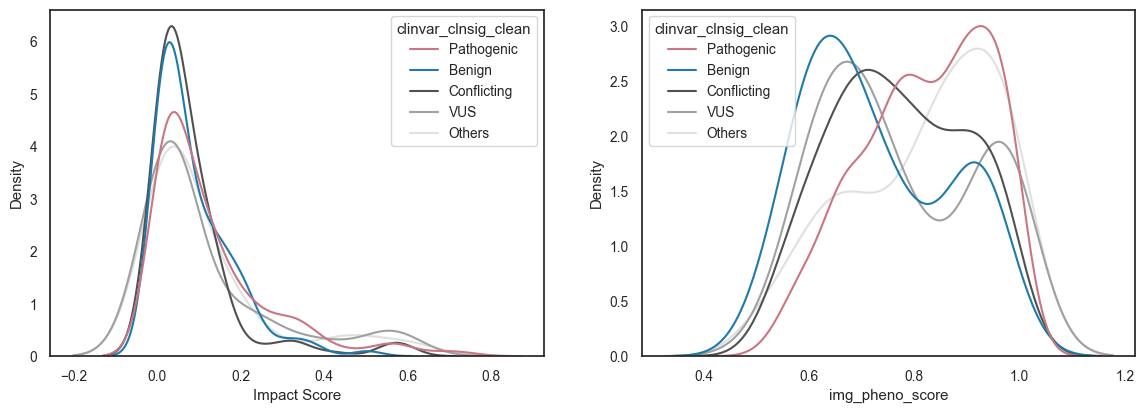

In [18]:
fig, axes = plt.subplots(1,2,figsize=(14, 4.5))

sns.kdeplot(
    data=records_df_plot.to_pandas(),
    x="Impact Score",
    # x="ClinVar Category",
    hue="clinvar_clnsig_clean",
    palette=palette_dict["clinvar_clnsig_clean"],
    # order=sorted(records_df_plot["clinvar_clnsig_clean"].unique()),
    # order=records_df_plot.group_by(
    #     "clinvar_clnsig_clean"
    # ).agg(
    #     pl.median("AUROC_Mean_GFP").alias("clinvar_median")
    # ).sort("clinvar_median", descending=True)["clinvar_clnsig_clean"],
    hue_order=[c for c in clinvar_order_dict["original"] if "Likely" not in c],
    common_norm=False,
    ax=axes[0]
)

sns.kdeplot(
    data=records_df_plot.to_pandas(),
    x="img_pheno_score",
    # x="ClinVar Category",
    hue="clinvar_clnsig_clean",
    palette=palette_dict["clinvar_clnsig_clean"],
    # order=sorted(records_df_plot["clinvar_clnsig_clean"].unique()),
    # order=records_df_plot.group_by(
    #     "clinvar_clnsig_clean"
    # ).agg(
    #     pl.median("AUROC_Mean_GFP").alias("clinvar_median")
    # ).sort("clinvar_median", descending=True)["clinvar_clnsig_clean"],
    hue_order=[c for c in clinvar_order_dict["original"] if "Likely" not in c],
    common_norm=False,
    ax=axes[1]
)
plt.show()